# Lab 7- Data Analysis


## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [3]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [13]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [14]:
FeatureNames

['R',
 'dPhi_r_b',
 'MT2',
 'cos_theta_r1',
 'M_TR_2',
 'M_Delta_R',
 'MET_rel',
 'S_R',
 'M_R',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [7]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [17]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4999995,1.0,0.853325,-0.961783,-1.487277,0.678190,0.493580,1.647969,1.843867,0.276954,1.025105,-1.486535,0.892879,1.684429,1.674084,3.366298,1.046707,2.646649,1.389226,0.364599
4999996,0.0,0.951581,0.139370,1.436884,0.880440,-0.351948,-0.740852,0.290863,-0.732360,0.001360,0.257738,0.802871,0.545319,0.602730,0.002998,0.748959,0.401166,0.443471,0.239953
4999997,0.0,0.840389,1.419162,-1.218766,1.195631,1.695645,0.663756,0.490888,-0.509186,0.704289,0.045744,0.825015,0.723530,0.778236,0.752942,0.838953,0.614048,1.210595,0.026692
4999998,1.0,1.784218,-0.833565,-0.560091,0.953342,-0.688969,-1.428233,2.660703,-0.861344,2.116892,2.906151,1.232334,0.952444,0.685846,0.000000,0.781874,0.676003,1.197807,0.093689


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [18]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


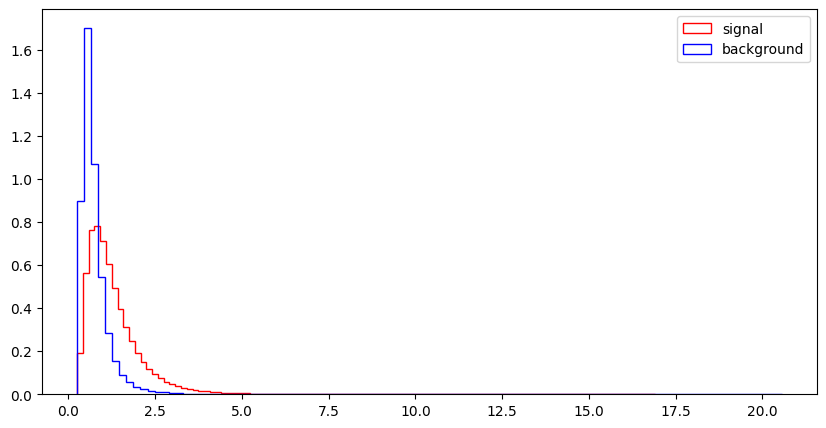

l_1_eta


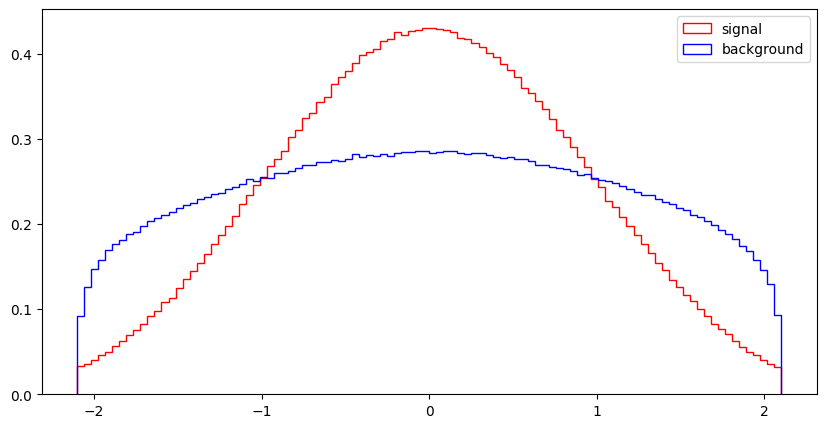

l_1_phi


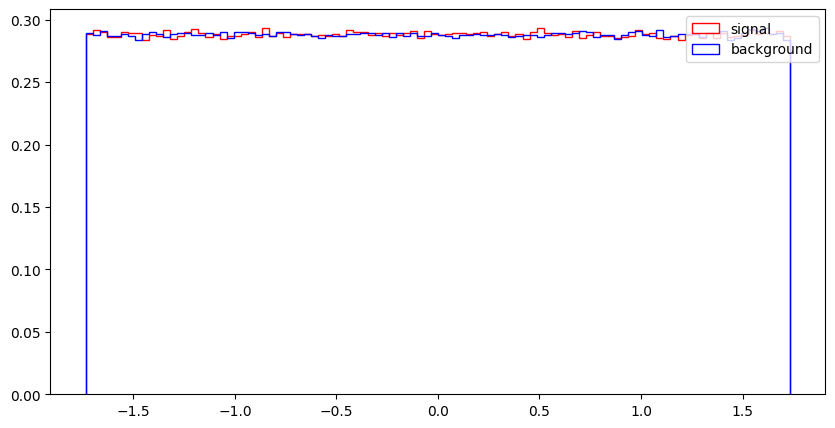

l_2_pT


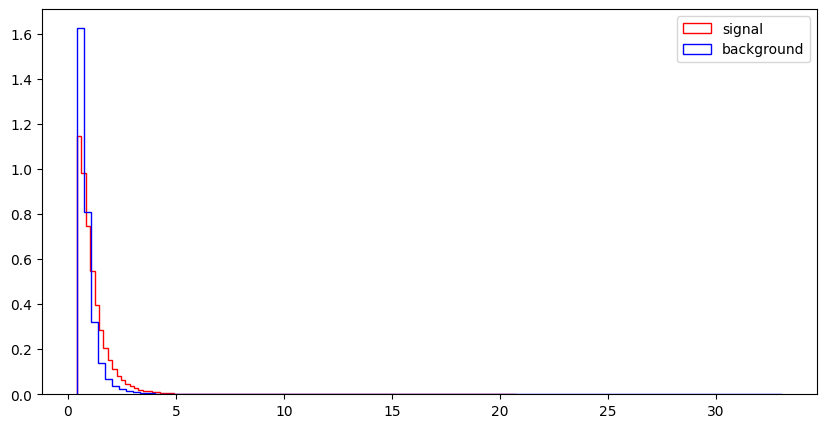

l_2_eta


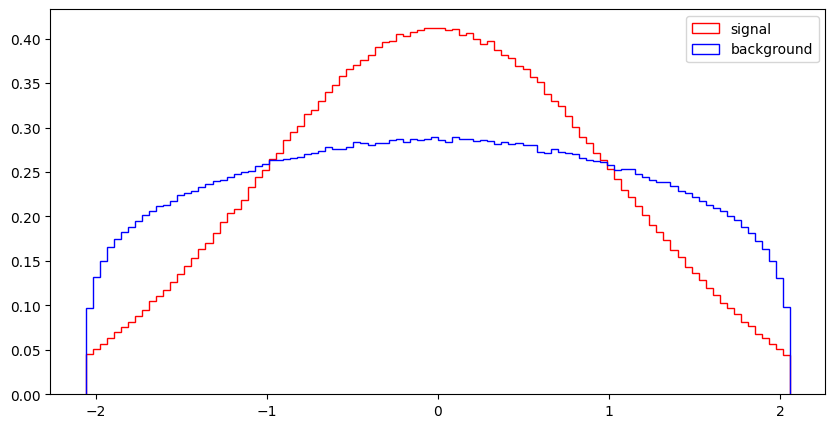

l_2_phi


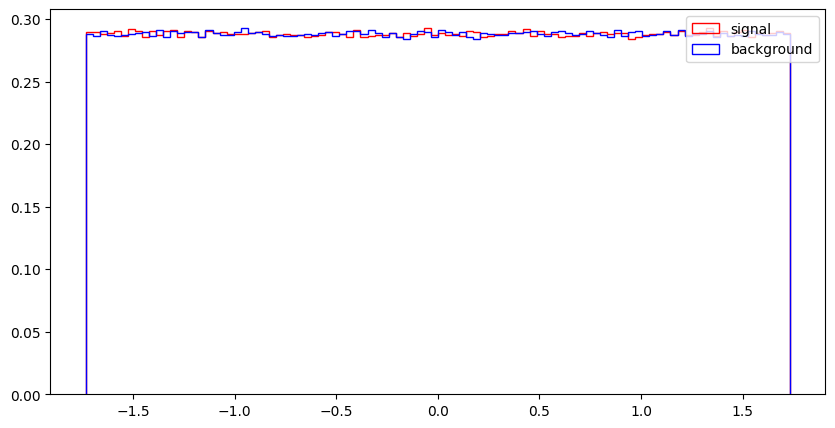

MET


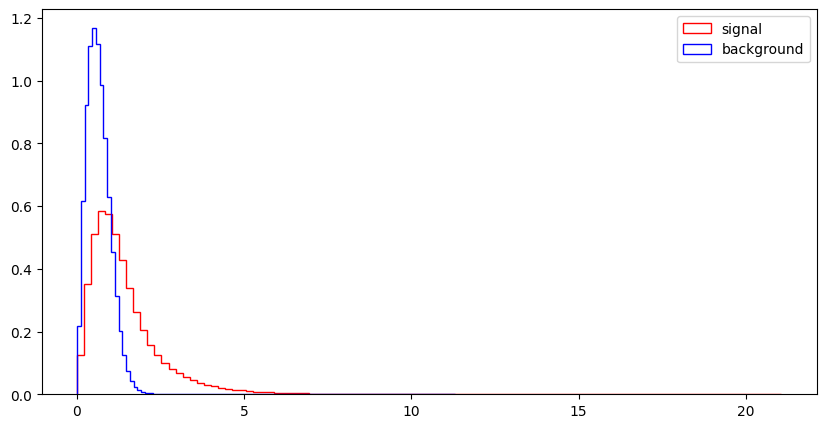

MET_phi


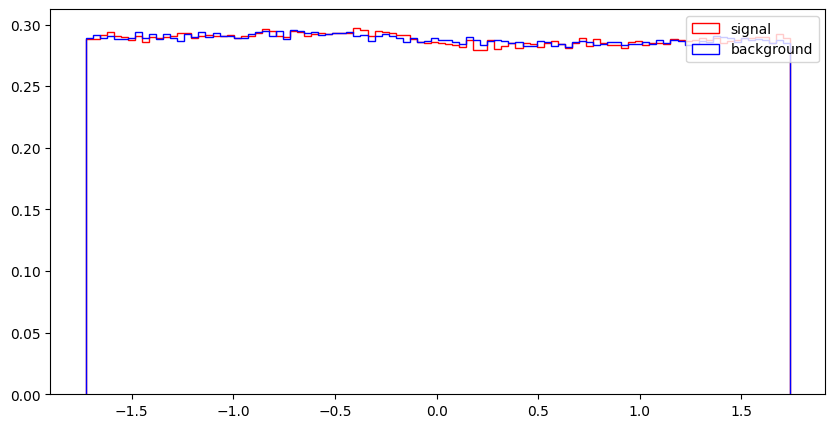

MET_rel


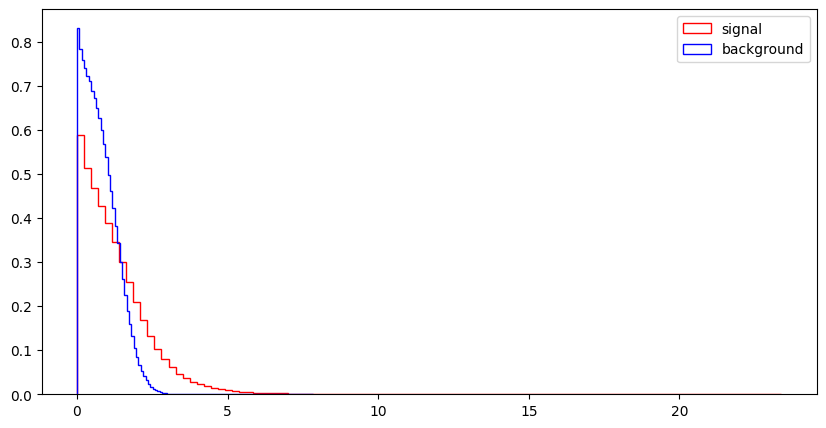

axial_MET


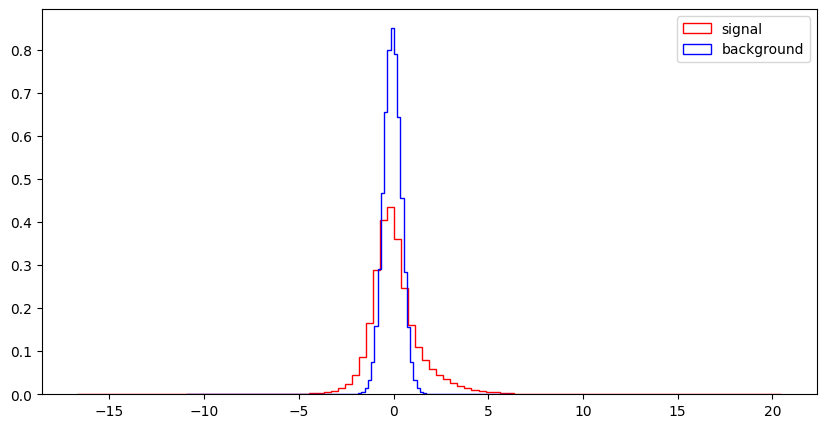

M_R


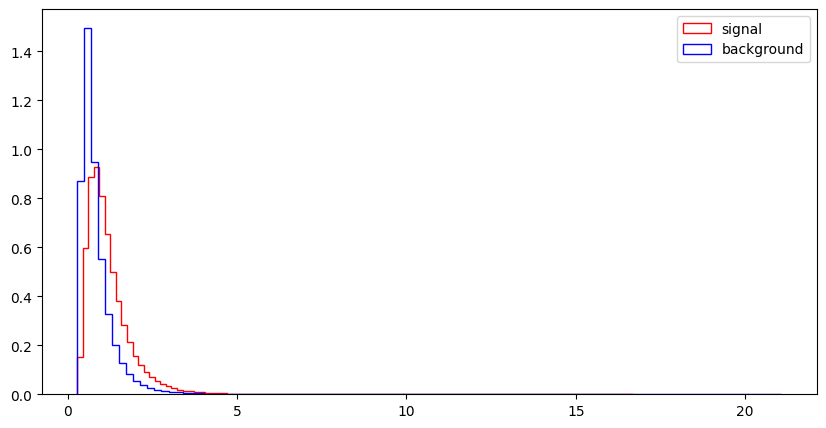

M_TR_2


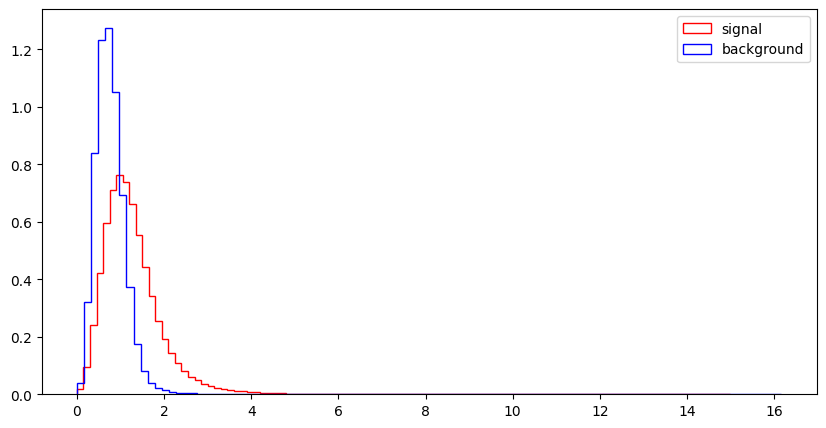

R


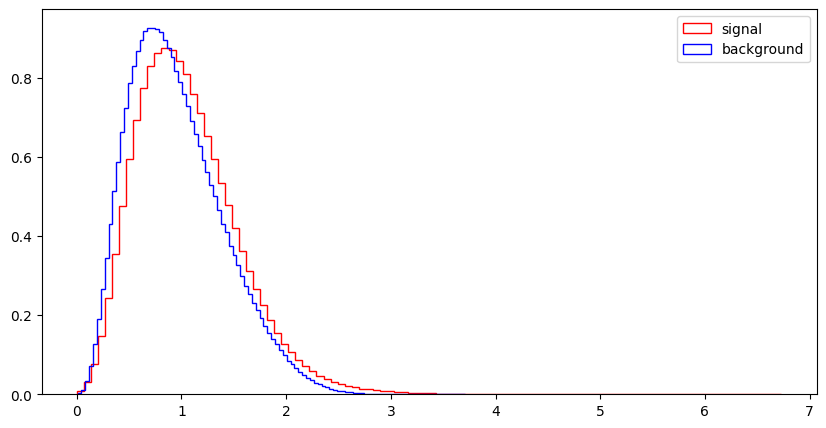

MT2


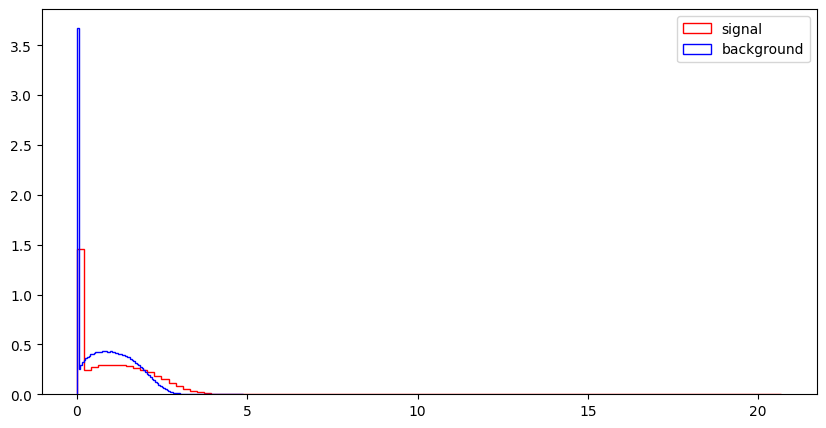

S_R


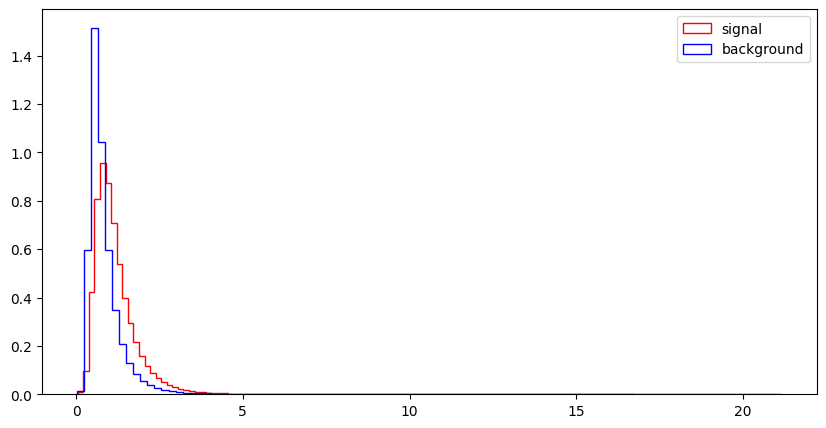

M_Delta_R


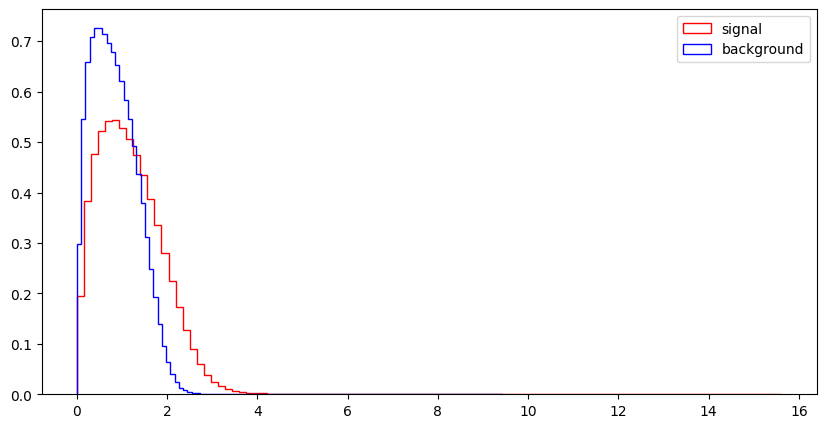

dPhi_r_b


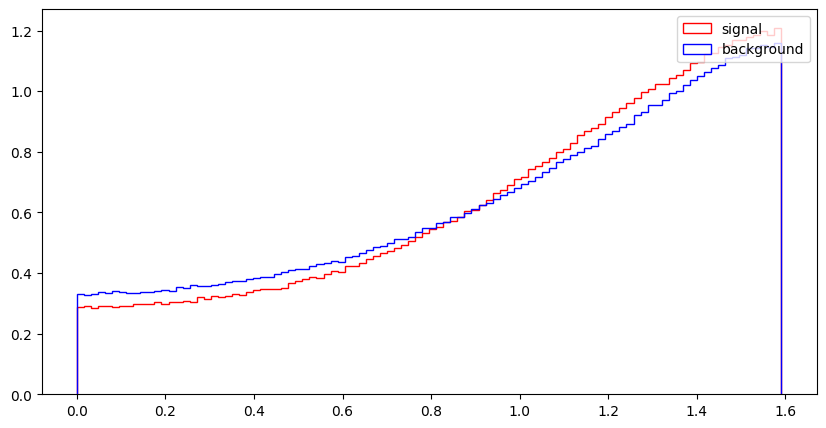

cos_theta_r1


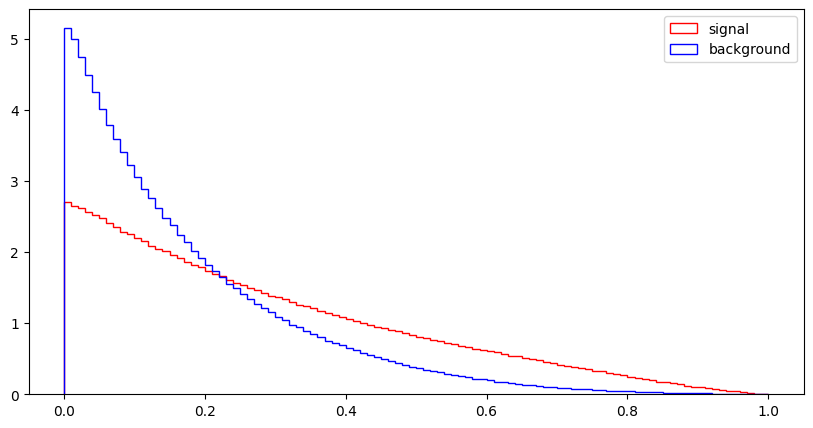

In [19]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

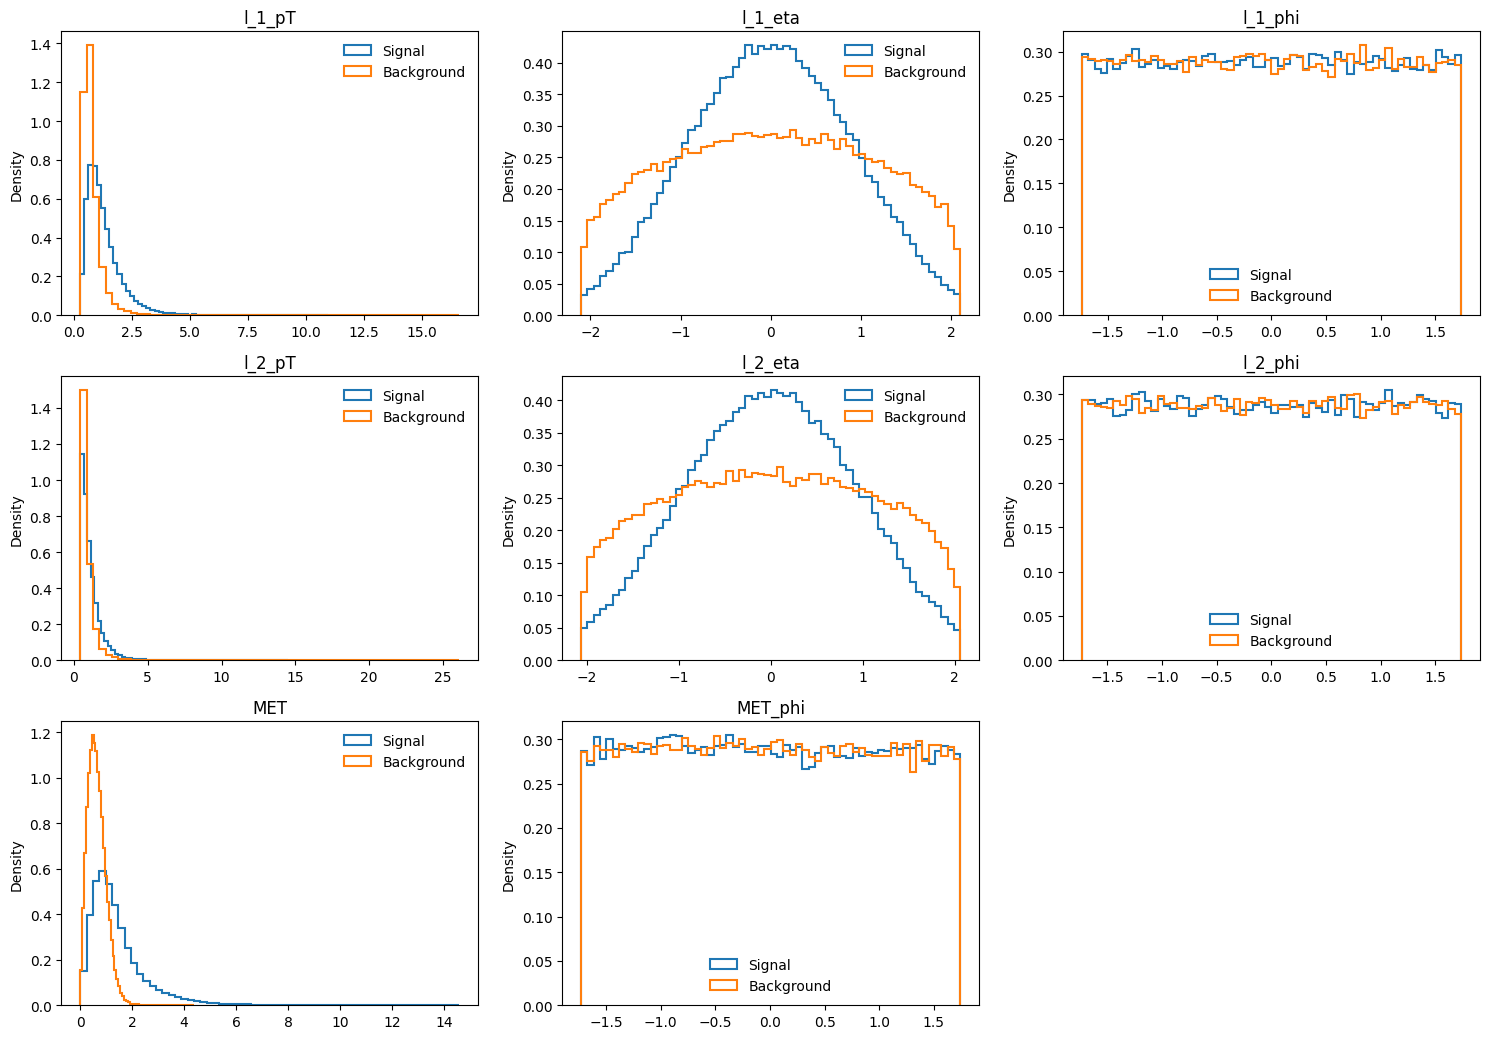

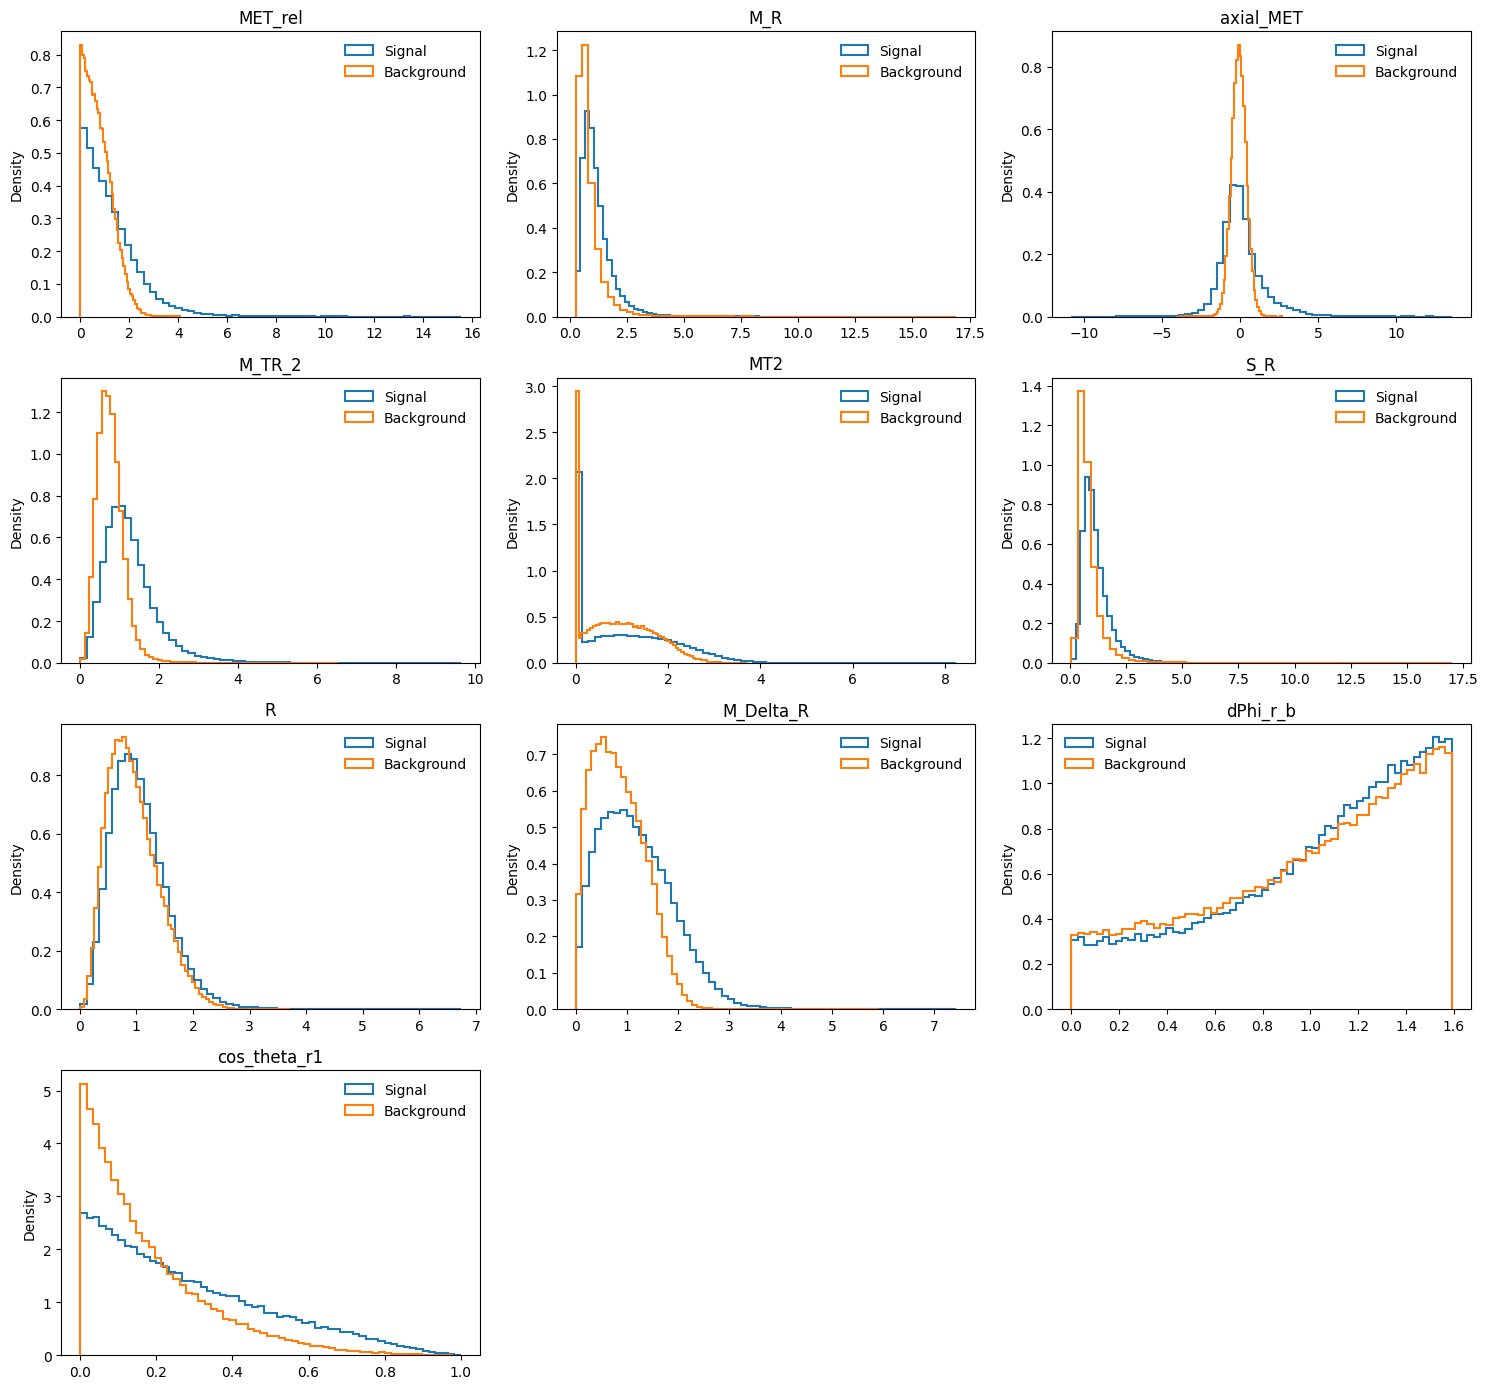

In [16]:
import numpy as np
import matplotlib.pyplot as plt

def plot_distributions(data, variables, ncols=3, bins=60, sample_size=100_000):
    sig = data[data["signal"] == 1]
    bkg = data[data["signal"] == 0]
    if len(sig) > sample_size:
        sig = sig.sample(sample_size, random_state=7)
    if len(bkg) > sample_size:
        bkg = bkg.sample(sample_size, random_state=7)
    nrows = int(np.ceil(len(variables) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.5*nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, var in zip(axes, variables):
        ax.hist(sig[var], bins=bins, density=True, histtype="step", linewidth=1.5, label="Signal")
        ax.hist(bkg[var], bins=bins, density=True, histtype="step", linewidth=1.5, label="Background")
        ax.set_title(var)
        ax.set_ylabel("Density")
        ax.legend(frameon=False)
    for ax in axes[len(variables):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

plot_distributions(df, RawNames)
plot_distributions(df, FeatureNames)

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

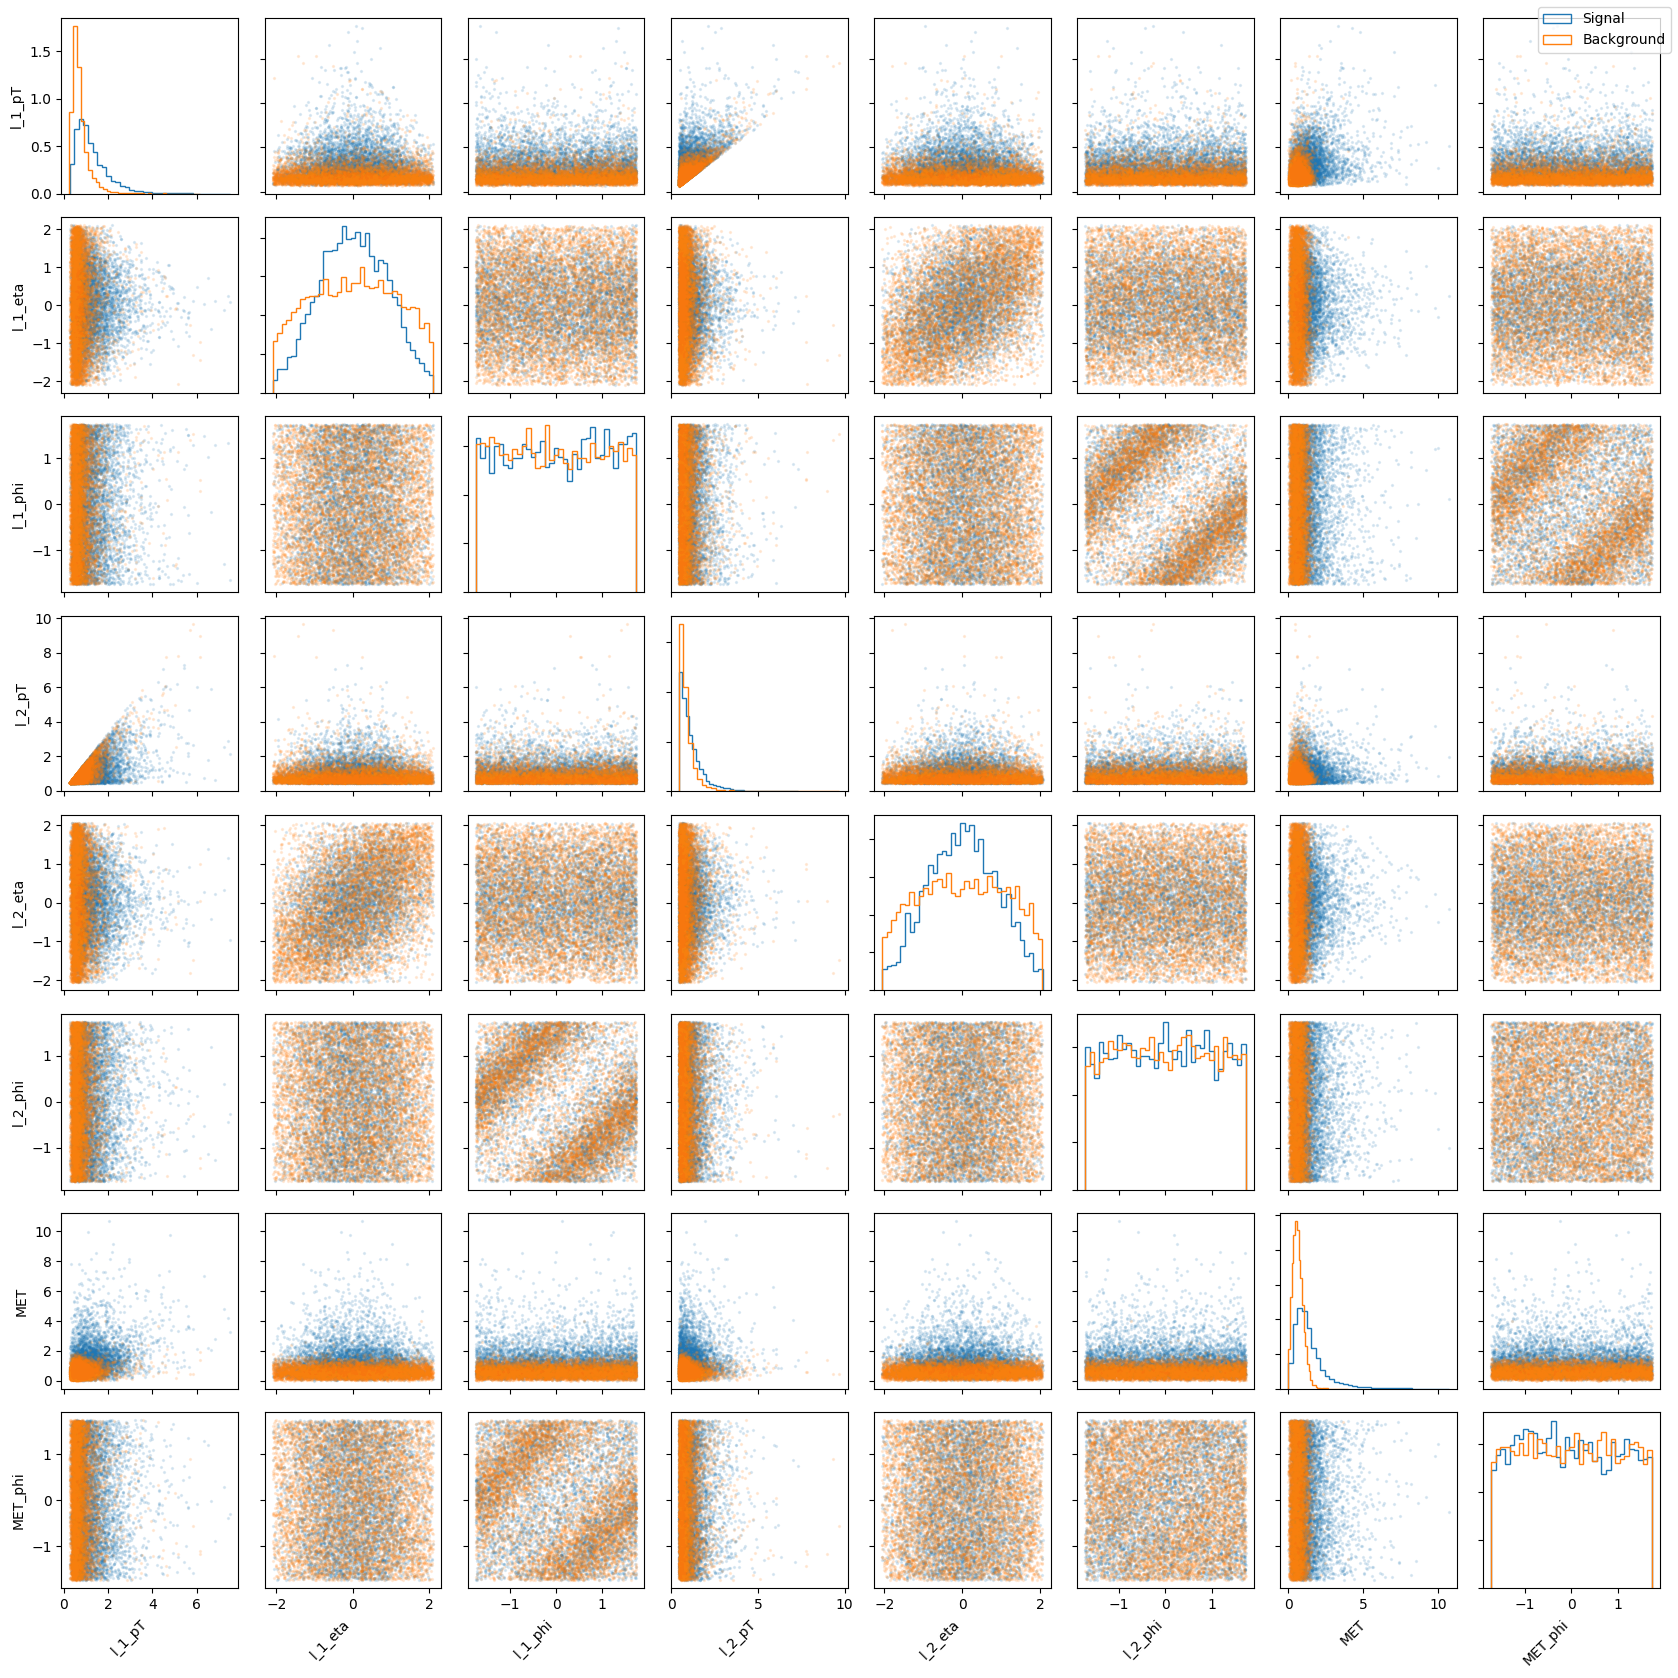

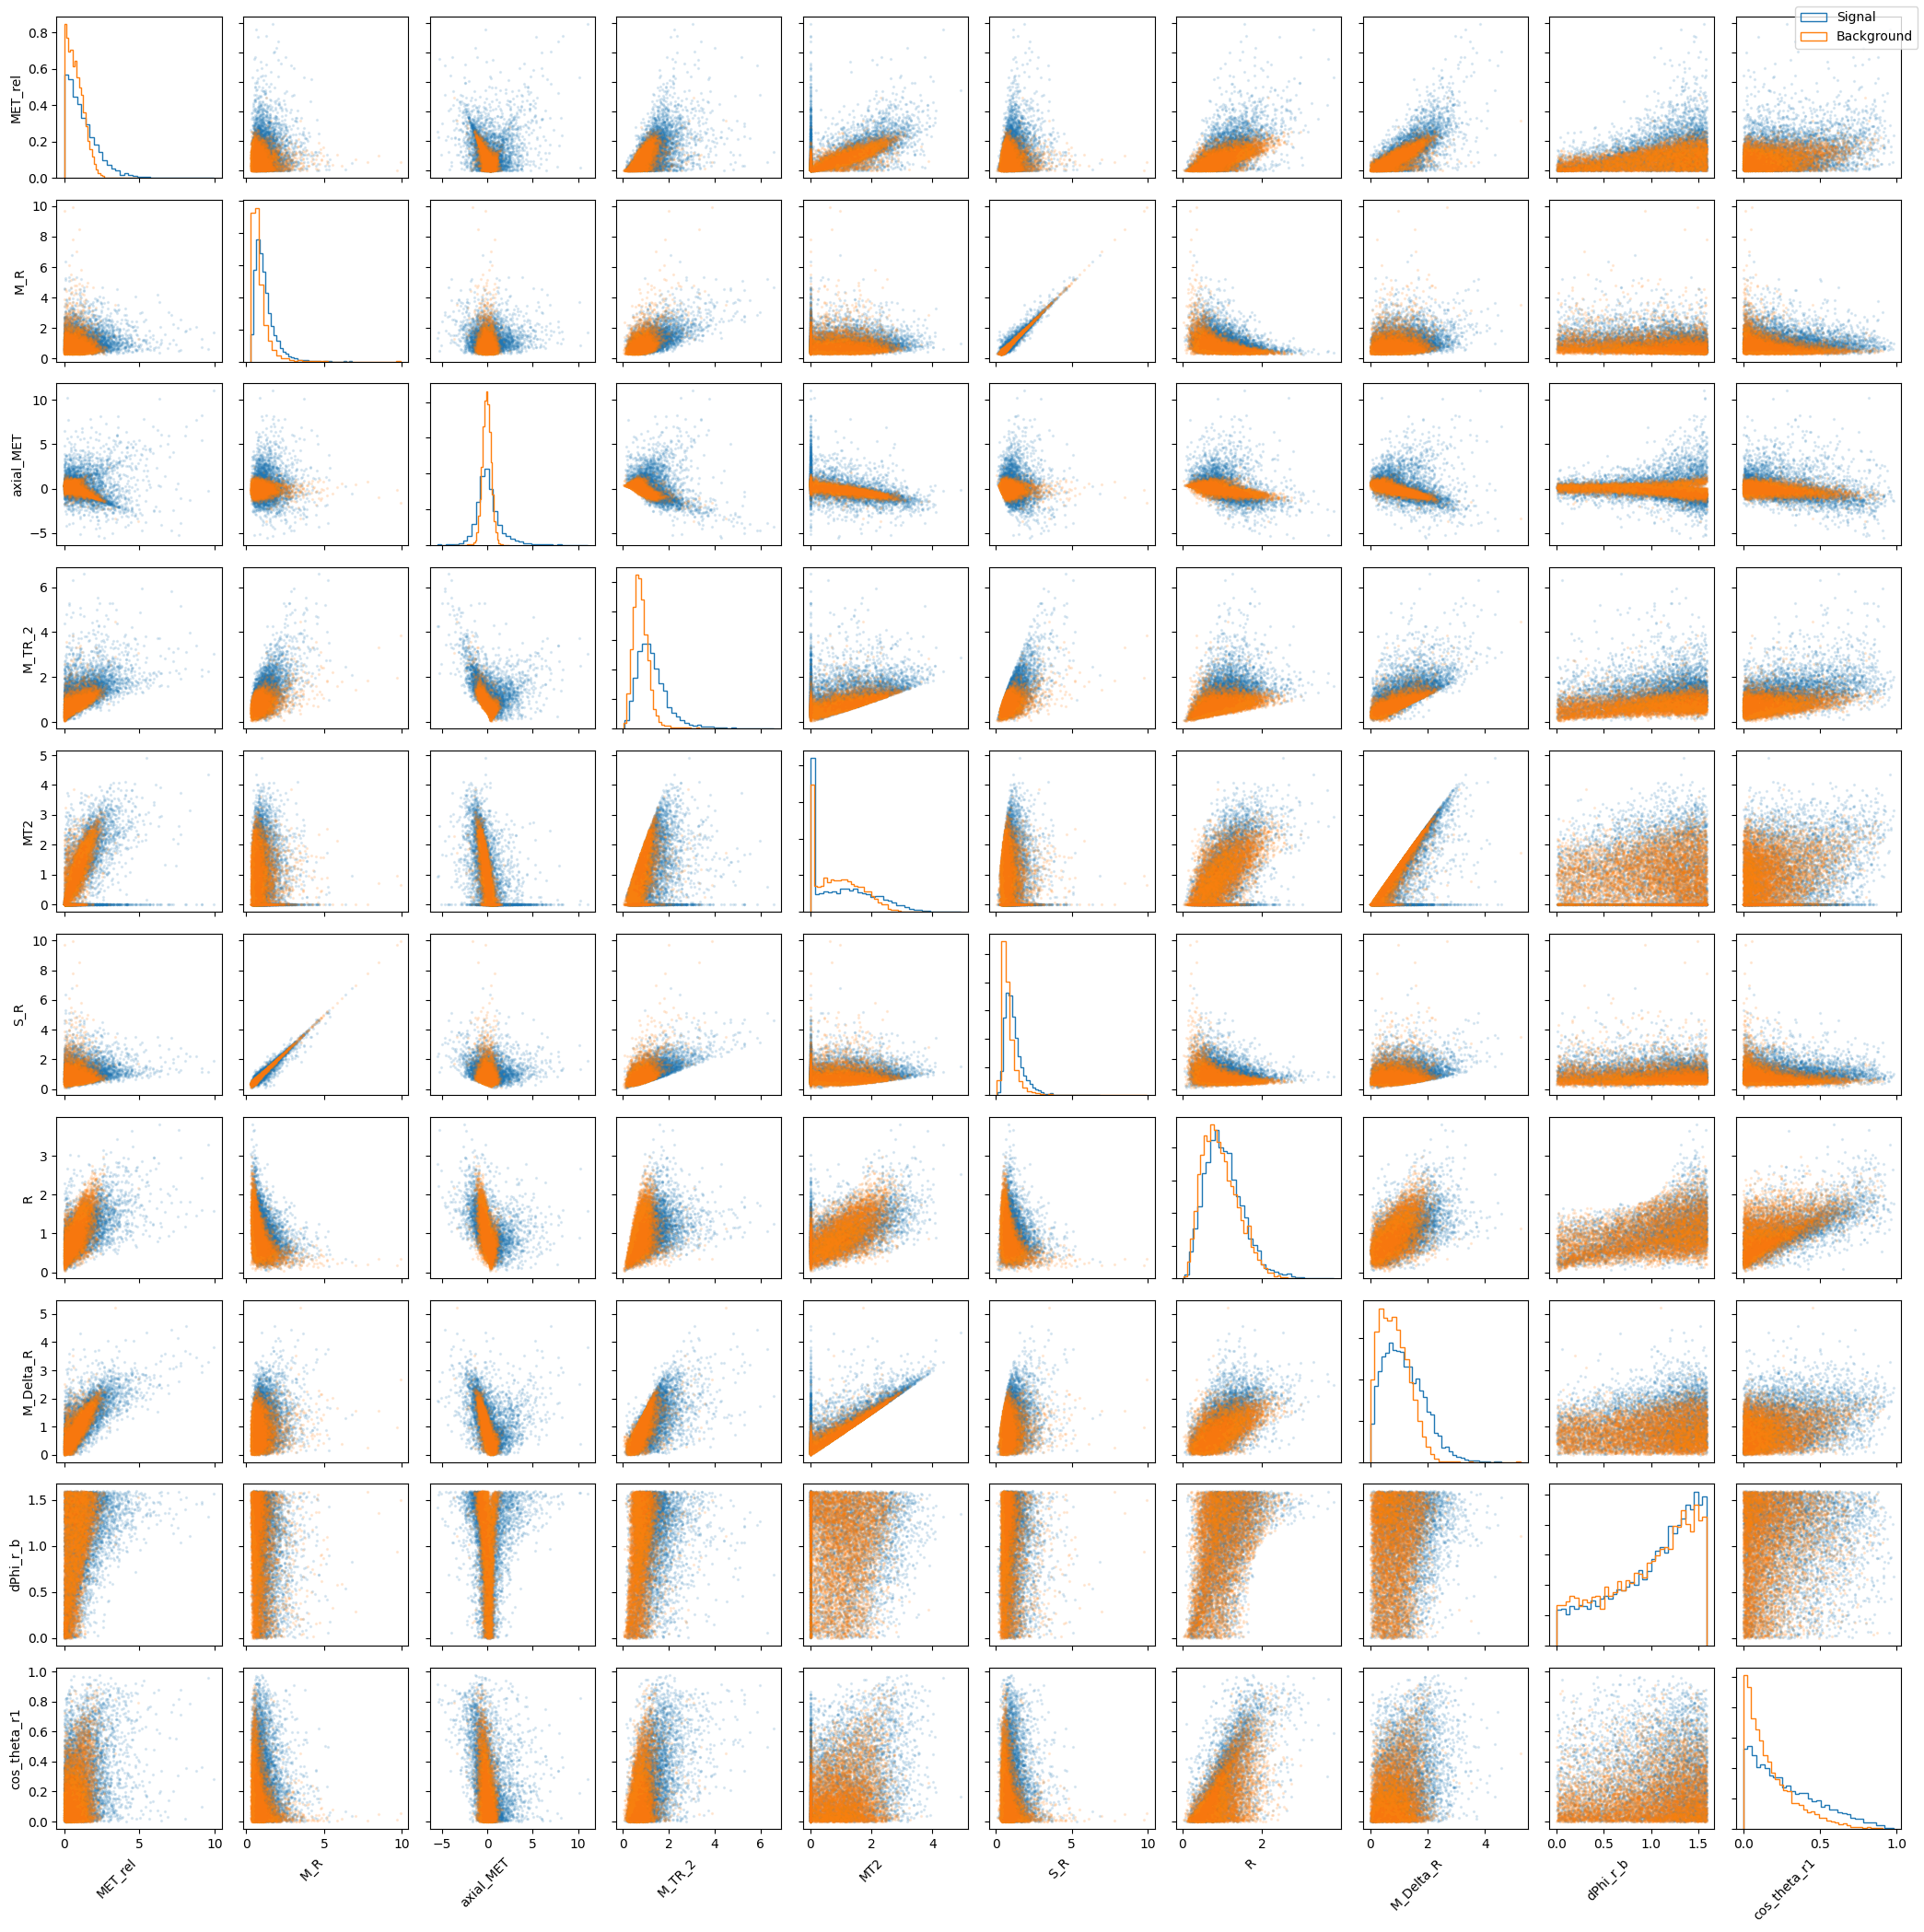

In [17]:
import numpy as np
import matplotlib.pyplot as plt

def pair_plot(data, variables, label_col="signal", sample_size=12_000, bins=35):
    cols = list(variables)
    sample = data[cols + [label_col]].sample(
        min(sample_size, len(data)), random_state=7
    )
    labels = [(1, "Signal"), (0, "Background")]
    n = len(cols)
    fig, axes = plt.subplots(n, n, figsize=(2.1*n, 2.1*n))
    for i, y in enumerate(cols):
        for j, x in enumerate(cols):
            ax = axes[i, j]
            for value, label in labels:
                d = sample.loc[sample[label_col] == value]
                if i == j:
                    ax.hist(d[x], bins=bins, density=True, histtype="step", label=label)
                else:
                    ax.scatter(d[x], d[y], s=2, alpha=0.12, rasterized=True,
                               label=label if (i, j) == (0, 0) else None)
            if i == n-1: ax.set_xlabel(x, rotation=45, ha="right")
            else: ax.set_xticklabels([])
            if j == 0: ax.set_ylabel(y)
            else: ax.set_yticklabels([])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    if handles: fig.legend(handles, labels, loc="upper right")
    fig.tight_layout()
    plt.show()

pair_plot(df, RawNames)
pair_plot(df, FeatureNames)

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

In [18]:
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from tabulate import tabulate

def show_matrix_tables(data, variables, title=""):
    values = data[list(variables)].dropna().to_numpy(dtype=float)
    cov = np.cov(values, rowvar=False)
    corr = np.corrcoef(values, rowvar=False)
    headers = ["Variable"] + list(variables)
    print(f"{title} — covariance matrix")
    display(HTML(tabulate(
        [[variables[i]] + [f"{v:.3g}" for v in row] for i, row in enumerate(cov)],
        headers=headers, tablefmt="html")))
    print(f"{title} — correlation matrix")
    display(HTML(tabulate(
        [[variables[i]] + [f"{v:.3f}" for v in row] for i, row in enumerate(corr)],
        headers=headers, tablefmt="html")))
    return cov, corr

all_vars = VarNames[1:]
cov_all, corr_all = show_matrix_tables(df, all_vars, "All observables")
cov_raw, corr_raw = show_matrix_tables(df, RawNames, "Raw observables")
cov_features, corr_features = show_matrix_tables(df, FeatureNames, "Derived features")

All observables — covariance matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


All observables — correlation matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


Raw observables — covariance matrix


...

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


Derived features — covariance matrix


Variable,MET_rel,M_R,axial_MET,M_TR_2,MT2,S_R,R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,0.0437,-0.12,0.302,0.409,0.0823,0.249,0.415,0.146,0.0553
M_R,0.0437,0.392,0.0171,0.21,-0.0365,0.38,-0.113,0.0739,-0.029,-0.0143
axial_MET,-0.12,0.0171,1.01,-0.185,-0.461,-0.0414,-0.181,-0.233,-0.0251,-0.0537
M_TR_2,0.302,0.21,-0.185,0.338,0.189,0.228,0.104,0.242,0.0581,0.0517
MT2,0.409,-0.0365,-0.461,0.189,0.738,-0.011,0.232,0.433,0.0209,0.0446
S_R,0.0823,0.38,-0.0414,0.228,-0.011,0.382,-0.0834,0.0958,-0.00346,-0.0104
R,0.249,-0.113,-0.181,0.104,0.232,-0.0834,0.222,0.165,0.0871,0.0582
M_Delta_R,0.415,0.0739,-0.233,0.242,0.433,0.0958,0.165,0.389,0.0422,0.0392
dPhi_r_b,0.146,-0.029,-0.0251,0.0581,0.0209,-0.00346,0.0871,0.0422,0.19,0.00908
cos_theta_r1,0.0553,-0.0143,-0.0537,0.0517,0.0446,-0.0104,0.0582,0.0392,0.00908,0.0388


Derived features — correlation matrix


Variable,MET_rel,M_R,axial_MET,M_TR_2,MT2,S_R,R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,0.078,-0.134,0.584,0.535,0.15,0.595,0.748,0.378,0.316
M_R,0.078,1,0.027,0.577,-0.068,0.981,-0.383,0.189,-0.106,-0.116
axial_MET,-0.134,0.027,1,-0.317,-0.535,-0.067,-0.383,-0.373,-0.057,-0.272
M_TR_2,0.584,0.577,-0.317,1,0.379,0.635,0.38,0.668,0.229,0.451
MT2,0.535,-0.068,-0.535,0.379,1,-0.021,0.574,0.809,0.056,0.264
S_R,0.15,0.981,-0.067,0.635,-0.021,1,-0.287,0.249,-0.013,-0.085
R,0.595,-0.383,-0.383,0.38,0.574,-0.287,1,0.564,0.424,0.627
M_Delta_R,0.748,0.189,-0.373,0.668,0.809,0.249,0.564,1,0.155,0.319
dPhi_r_b,0.378,-0.106,-0.057,0.229,0.056,-0.013,0.424,0.155,1,0.106
cos_theta_r1,0.316,-0.116,-0.272,0.451,0.264,-0.085,0.627,0.319,0.106,1


Hint: Example code for embedding a `tabulate` table into a notebook:

In [ ]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

l_1_pT          strategy=gt      threshold=0.9567; max significance=11.77
l_1_eta         strategy=abs_lt  threshold=1.544; max significance=9.759
l_1_phi         strategy=abs_gt  threshold=-1.701; max significance=9.535
l_2_pT          strategy=gt      threshold=0.4354; max significance=9.517
l_2_eta         strategy=abs_lt  threshold=1.661; max significance=9.62
l_2_phi         strategy=abs_gt  threshold=-1.7; max significance=9.535
MET             strategy=gt      threshold=1.533; max significance=14.99
MET_phi         strategy=abs_gt  threshold=-1.692; max significance=9.535
MET_rel         strategy=abs_gt  threshold=1.298; max significance=9.726
axial_MET       strategy=abs_gt  threshold=1.251; max significance=13.18
M_R             strategy=gt      threshold=0.6818; max significance=10.49
M_TR_2          strategy=gt      threshold=1.31; max significance=12.71
R               strategy=abs_lt  threshold=2.321; max significance=9.525
MT2             strategy=abs_gt  threshold=0; max

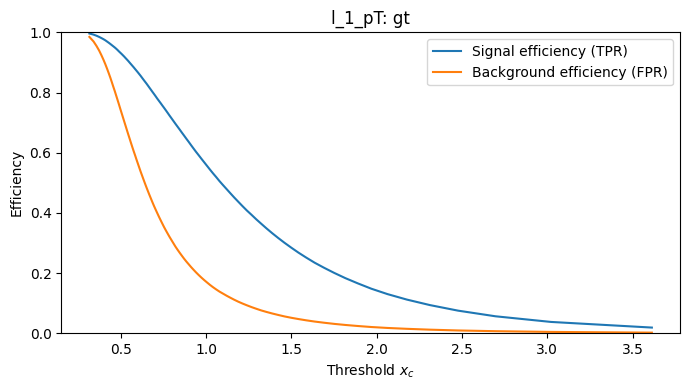

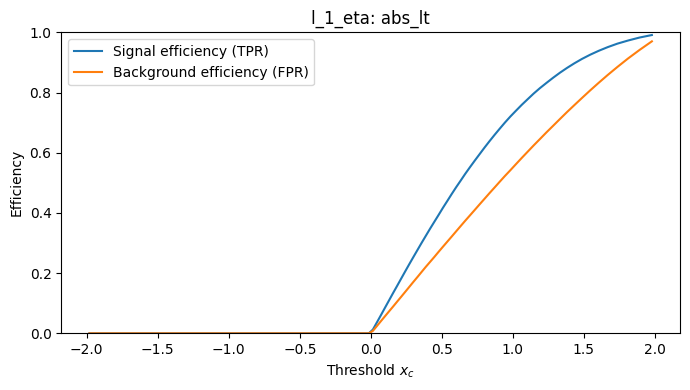

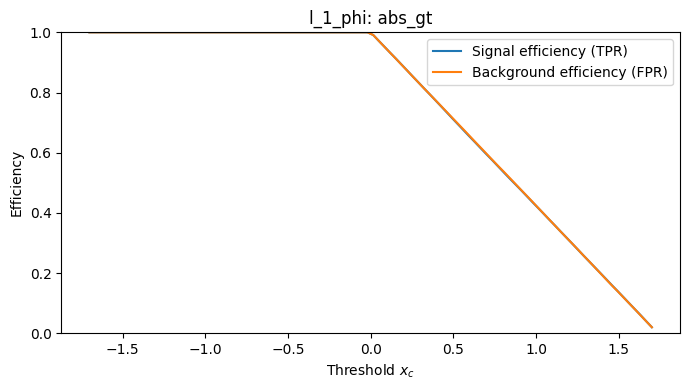

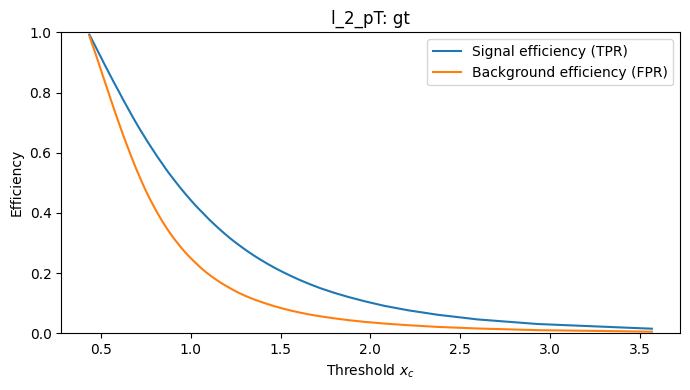

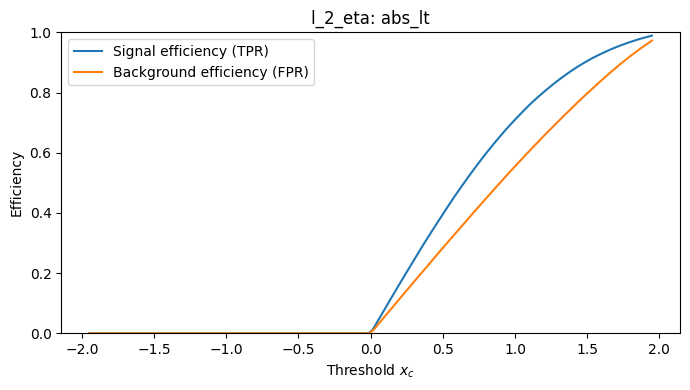

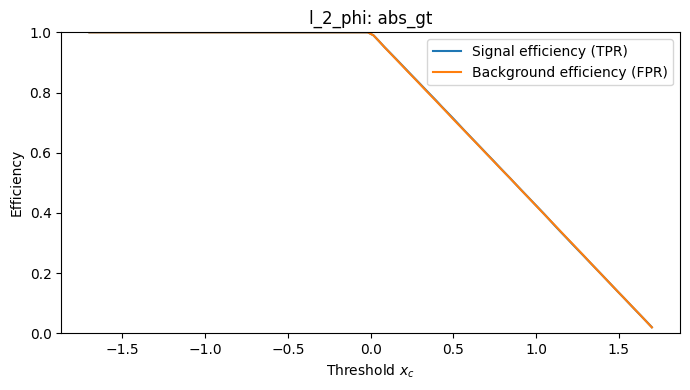

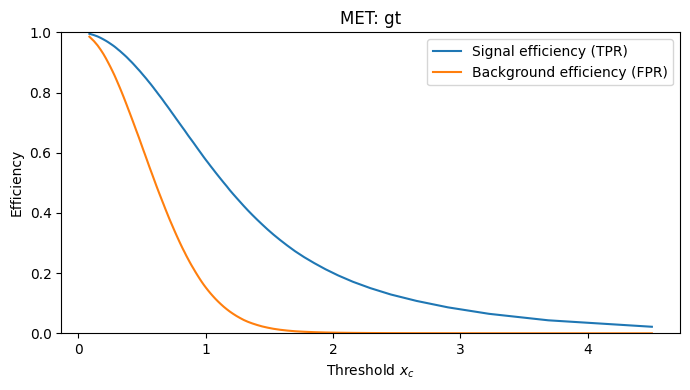

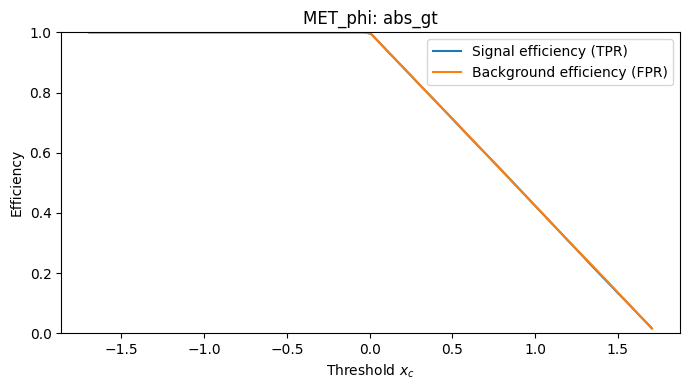

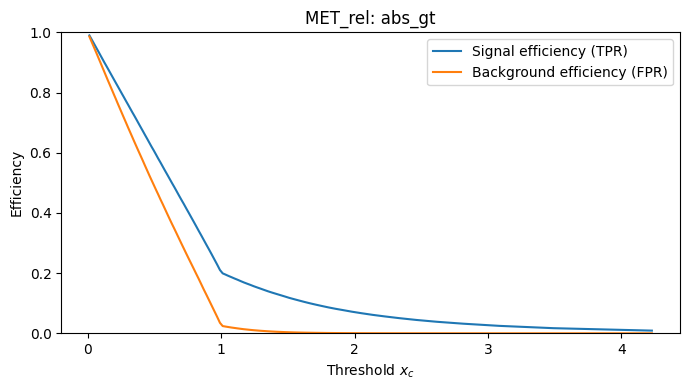

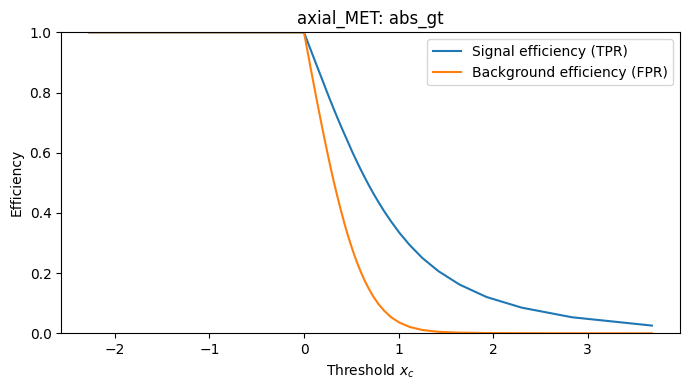

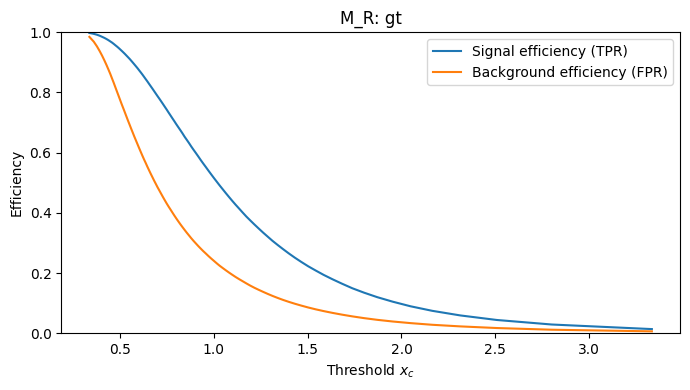

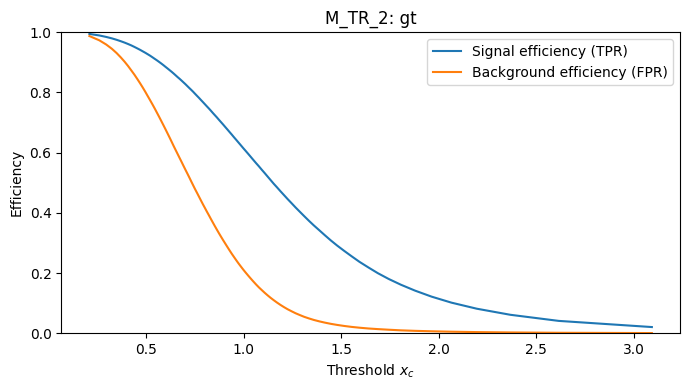

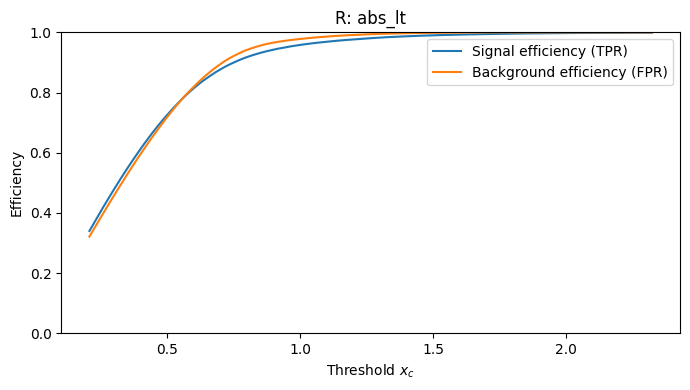

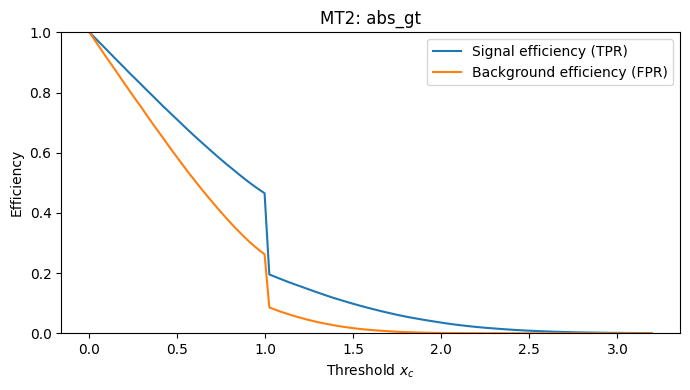

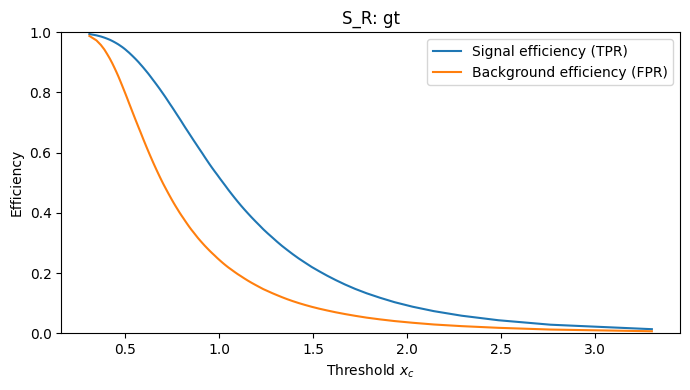

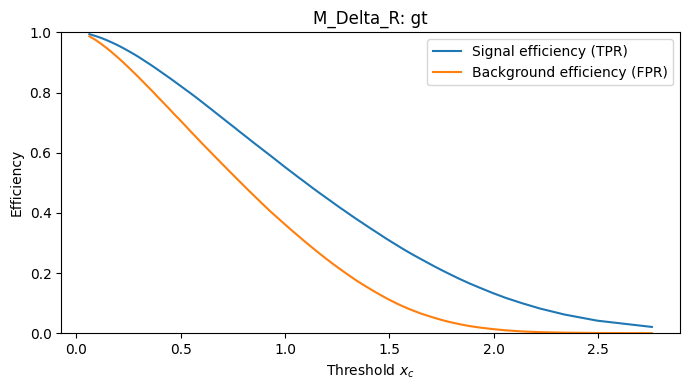

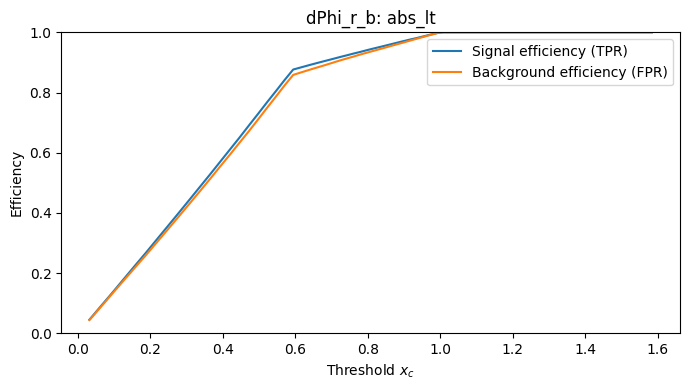

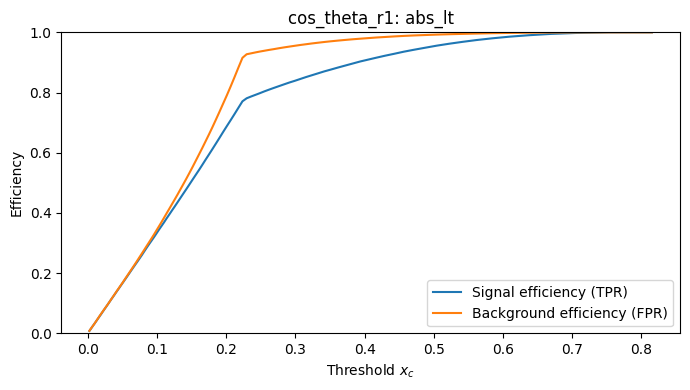

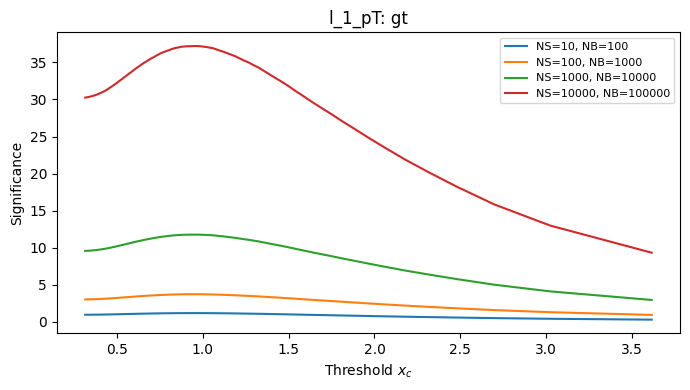

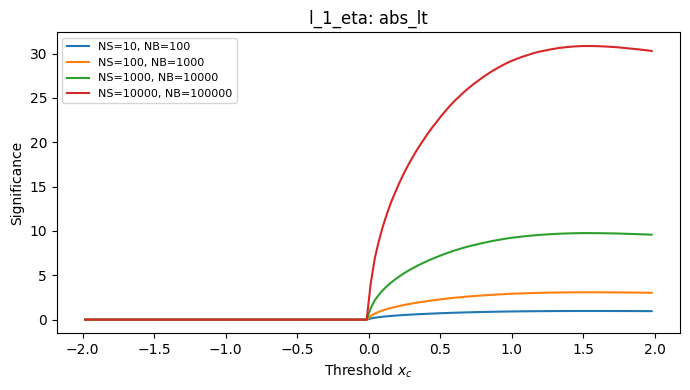

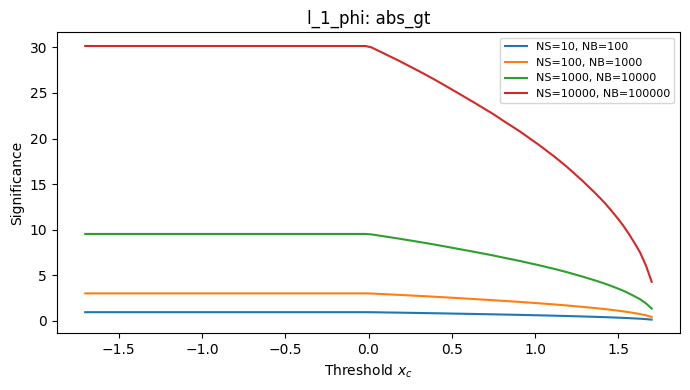

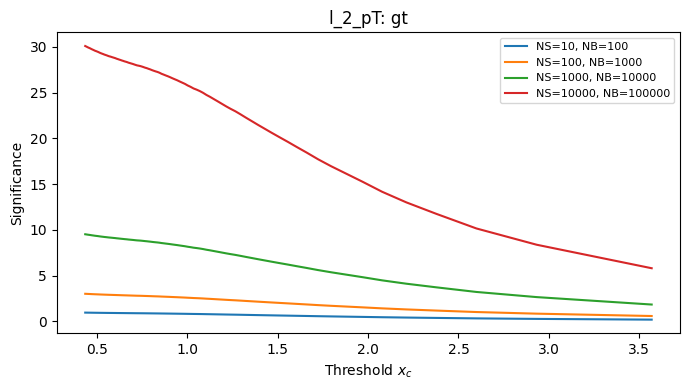

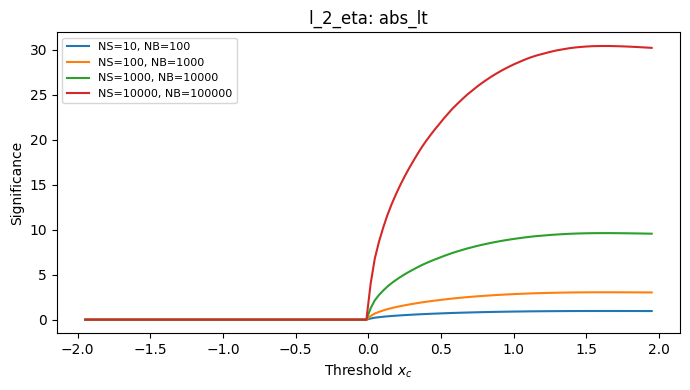

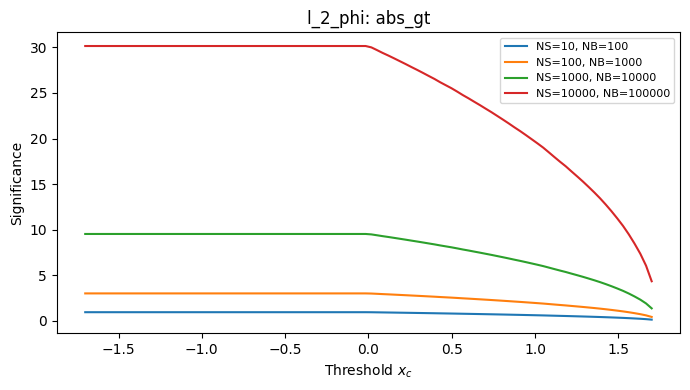

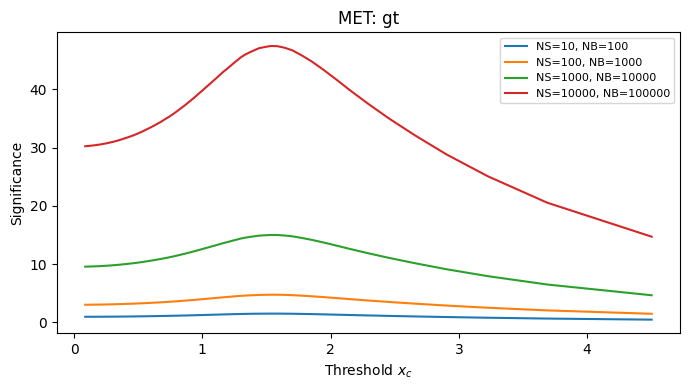

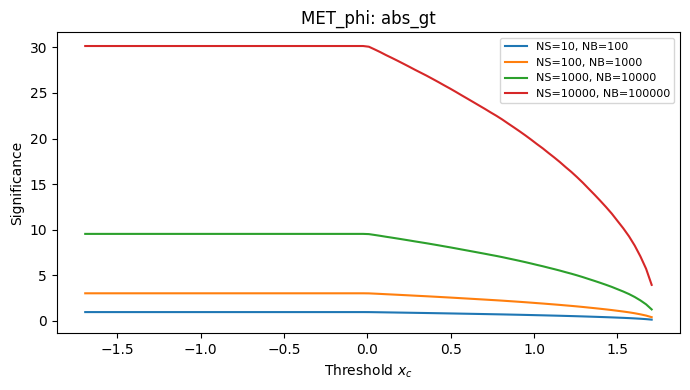

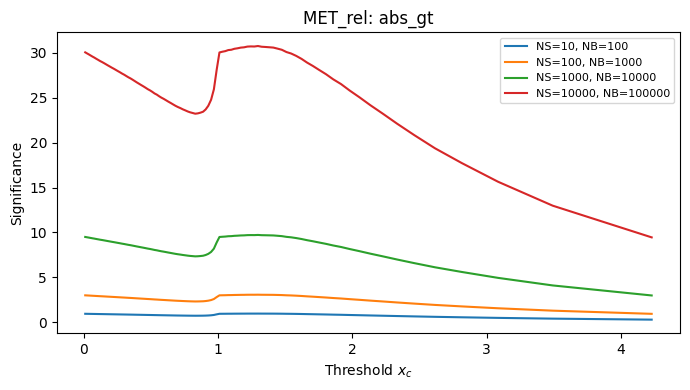

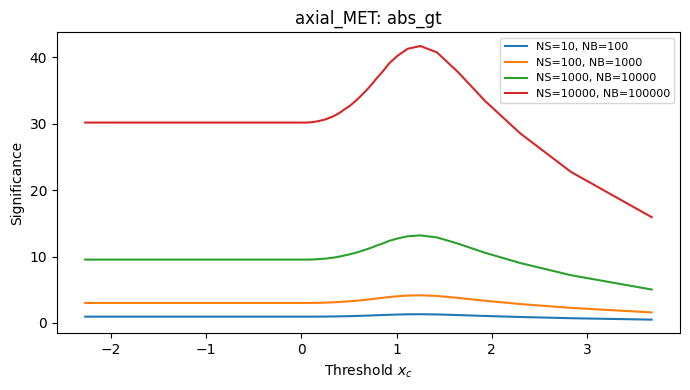

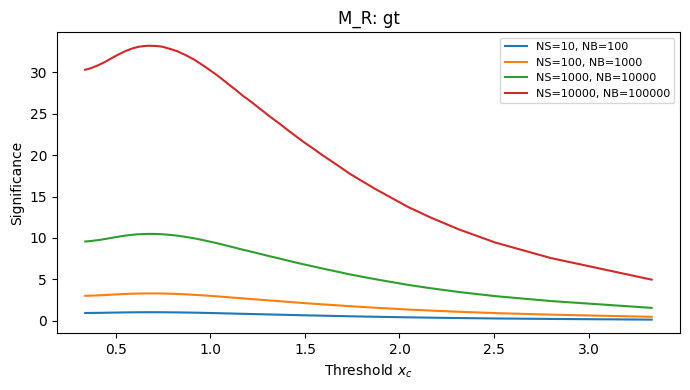

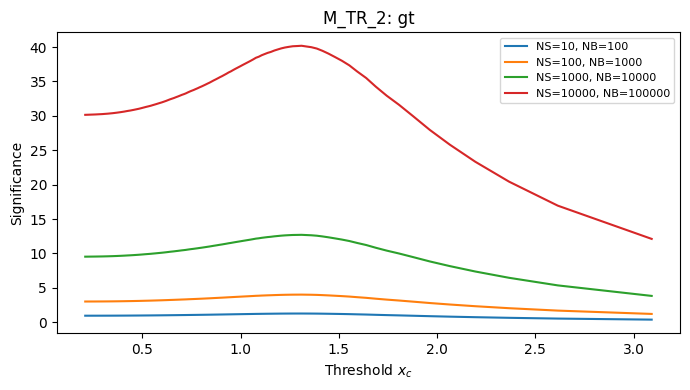

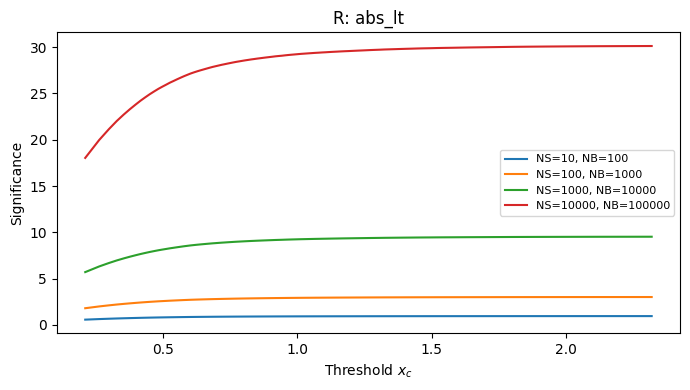

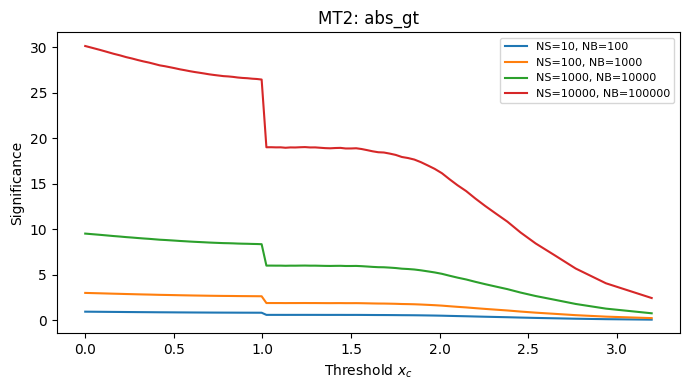

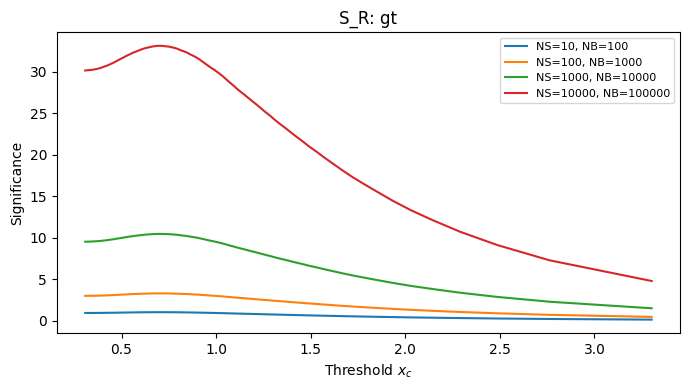

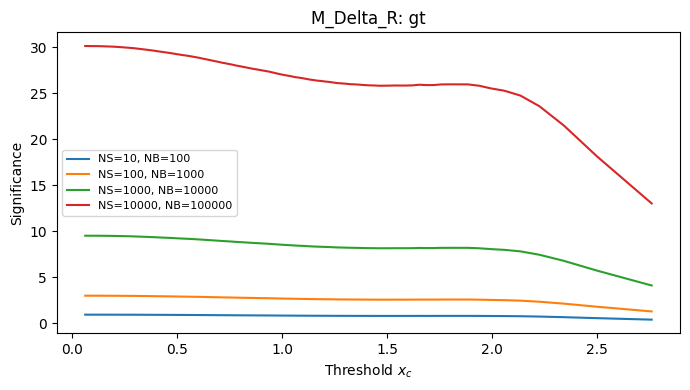

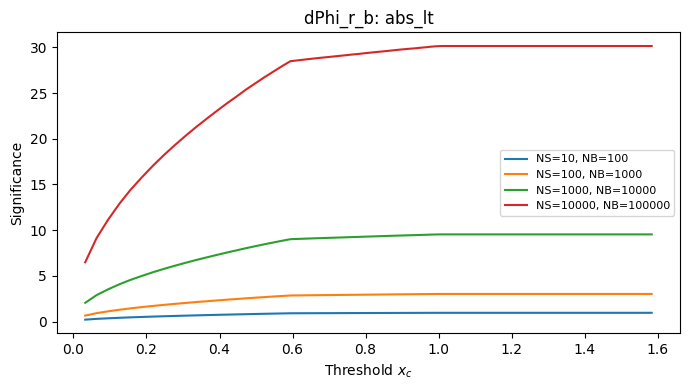

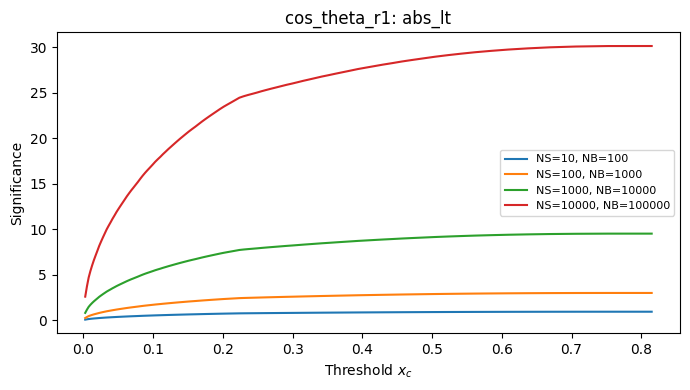

In [19]:
import numpy as np
import matplotlib.pyplot as plt

SCENARIOS = [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]

def threshold_scan(signal, background, variable, strategy, n_thresholds=100):
    """Return thresholds, signal efficiency, background efficiency.
    strategy is 'gt', 'lt', 'abs_gt', or 'abs_lt'."""
    s = np.asarray(signal[variable].dropna())
    b = np.asarray(background[variable].dropna())
    pooled = np.concatenate([s, b])
    thresholds = np.unique(np.quantile(pooled, np.linspace(0.01, 0.99, n_thresholds)))
    mu = np.mean(pooled)
    if strategy == "gt":
        es = np.array([(s > c).mean() for c in thresholds])
        eb = np.array([(b > c).mean() for c in thresholds])
    elif strategy == "lt":
        es = np.array([(s < c).mean() for c in thresholds])
        eb = np.array([(b < c).mean() for c in thresholds])
    elif strategy == "abs_gt":
        es = np.array([(np.abs(s-mu) > c).mean() for c in thresholds])
        eb = np.array([(np.abs(b-mu) > c).mean() for c in thresholds])
    elif strategy == "abs_lt":
        es = np.array([(np.abs(s-mu) < c).mean() for c in thresholds])
        eb = np.array([(np.abs(b-mu) < c).mean() for c in thresholds])
    else:
        raise ValueError("strategy must be gt, lt, abs_gt, or abs_lt")
    return thresholds, es, eb, mu

def best_strategy(signal, background, variable):
    options = ["gt", "lt", "abs_gt", "abs_lt"]
    best = None
    for strategy in options:
        x, es, eb, mu = threshold_scan(signal, background, variable, strategy)
        ns, nb = SCENARIOS[2]
        sig = es*ns / np.sqrt(np.maximum(es*ns + eb*nb, 1e-12))
        idx = int(np.argmax(sig))
        candidate = (sig[idx], strategy, x, es, eb, mu, idx)
        if best is None or candidate[0] > best[0]:
            best = candidate
    return best

best_by_var = {v: best_strategy(df_sig, df_bkg, v) for v in VarNames[1:]}
for v, (peak, strategy, x, es, eb, mu, idx) in best_by_var.items():
    print(f"{v:15s} strategy={strategy:7s} threshold={x[idx]:.4g}; max significance={peak:.4g}")

for v, (peak, strategy, x, es, eb, mu, idx) in best_by_var.items():
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(x, es, label="Signal efficiency (TPR)")
    ax.plot(x, eb, label="Background efficiency (FPR)")
    ax.set(xlabel="Threshold $x_c$", ylabel="Efficiency", title=f"{v}: {strategy}")
    ax.set_ylim(0, 1)
    ax.legend()
    fig.tight_layout()
    plt.show()

for v, (peak, strategy, x, es, eb, mu, idx) in best_by_var.items():
    fig, ax = plt.subplots(figsize=(7, 4))
    for ns, nb in SCENARIOS:
        sig = es*ns / np.sqrt(np.maximum(es*ns + eb*nb, 1e-12))
        ax.plot(x, sig, label=f"NS={ns}, NB={nb}")
    ax.set(xlabel="Threshold $x_c$", ylabel="Significance", title=f"{v}: {strategy}")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [20]:
import pandas as pd
import numpy as np

top3 = sorted(best_by_var, key=lambda v: best_by_var[v][0], reverse=True)[:3]
print("Top three observables from the single-variable scan:", top3)

def passes_cut(frame, variable, strategy, threshold, mu):
    x = frame[variable].to_numpy()
    if strategy == "gt": return x > threshold
    if strategy == "lt": return x < threshold
    if strategy == "abs_gt": return np.abs(x-mu) > threshold
    if strategy == "abs_lt": return np.abs(x-mu) < threshold
    raise ValueError(strategy)

def cutflow(signal, background, variables, scenario=(1000, 10000), order=None):
    ns0, nb0 = scenario
    order = list(order or variables)
    s_mask = np.ones(len(signal), dtype=bool)
    b_mask = np.ones(len(background), dtype=bool)
    rows = [{"Selection":"No cuts", "epsilon_S":1.0, "epsilon_B":1.0,
             "N_S'":ns0, "N_B'":nb0,
             "significance":ns0/np.sqrt(ns0+nb0)}]
    for v in order:
        _, strategy, x, es, eb, mu, idx = best_by_var[v]
        s_mask &= passes_cut(signal, v, strategy, x[idx], mu)
        b_mask &= passes_cut(background, v, strategy, x[idx], mu)
        eps_s, eps_b = s_mask.mean(), b_mask.mean()
        ns, nb_ = ns0*eps_s, nb0*eps_b
        rows.append({"Selection":f"{v} ({strategy}, {x[idx]:.3g})",
                     "epsilon_S":eps_s, "epsilon_B":eps_b, "N_S'":ns,
                     "N_B'":nb_, "significance":ns/np.sqrt(max(ns+nb_, 1e-12))})
    return pd.DataFrame(rows)

cutflow_tables = {}
for scenario in SCENARIOS:
    cutflow_tables[scenario] = cutflow(df_sig, df_bkg, top3, scenario)
    print("\\nScenario", scenario)
    display(cutflow_tables[scenario].round(4))

if len(top3) >= 2:
    print("Order A then B:")
    display(cutflow(df_sig, df_bkg, top3[:2], SCENARIOS[2]).round(4))
    print("Order B then A:")
    display(cutflow(df_sig, df_bkg, top3[:2], SCENARIOS[2], order=top3[1::-1]).round(4))

Top three observables from the single-variable scan: ['MET', 'axial_MET', 'M_TR_2']
\nScenario (10, 100)


,Selection,epsilon_S,epsilon_B,N_S',N_B',significance
0,No cuts,1.0000,1.0000,10.0000,100.0000,0.9535
1,"MET (gt, 1.53)",0.3279,0.0150,3.2791,1.5036,1.4994
2,"axial_MET (abs_gt, 1.25)",0.2219,0.0082,2.2188,0.8173,1.2734
3,"M_TR_2 (gt, 1.31)",0.1563,0.0069,1.5626,0.6899,1.0412


\nScenario (100, 1000)


,Selection,epsilon_S,epsilon_B,N_S',N_B',significance
0,No cuts,1.0000,1.0000,100.0000,1000.0000,3.0151
1,"MET (gt, 1.53)",0.3279,0.0150,32.7911,15.0357,4.7415
2,"axial_MET (abs_gt, 1.25)",0.2219,0.0082,22.1885,8.1734,4.0268
3,"M_TR_2 (gt, 1.31)",0.1563,0.0069,15.6261,6.8992,3.2924


\nScenario (1000, 10000)


...

,Selection,epsilon_S,epsilon_B,N_S',N_B',significance
0,No cuts,1.0000,1.0000,10000.0000,100000.0000,30.1511
1,"MET (gt, 1.53)",0.3279,0.0150,3279.1119,1503.5733,47.4155
2,"axial_MET (abs_gt, 1.25)",0.2219,0.0082,2218.8488,817.3441,40.2683
3,"M_TR_2 (gt, 1.31)",0.1563,0.0069,1562.6077,689.9226,32.9242


Order A then B:


,Selection,epsilon_S,epsilon_B,N_S',N_B',significance
0,No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
1,"MET (gt, 1.53)",0.3279,0.0150,327.9112,150.3573,14.9941
2,"axial_MET (abs_gt, 1.25)",0.2219,0.0082,221.8849,81.7344,12.7339


Order B then A:


,Selection,epsilon_S,epsilon_B,N_S',N_B',significance
0,No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
1,"axial_MET (abs_gt, 1.25)",0.2505,0.0111,250.5398,111.0229,13.1760
2,"MET (gt, 1.53)",0.2219,0.0082,221.8849,81.7344,12.7339


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



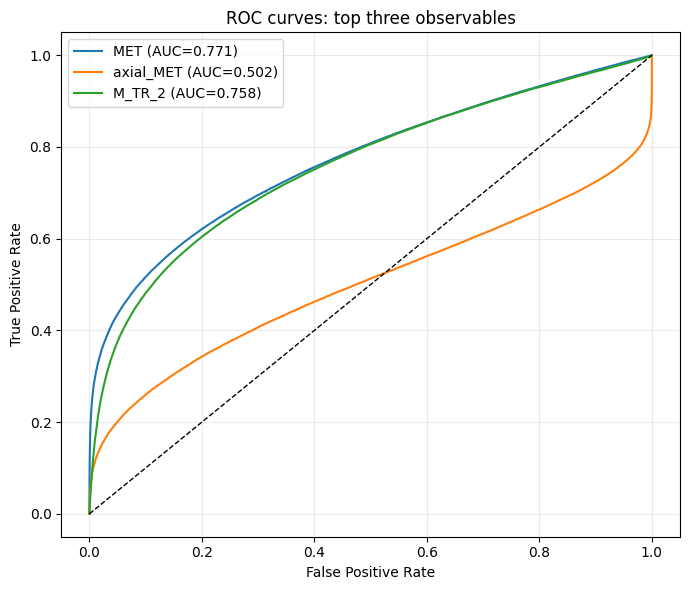

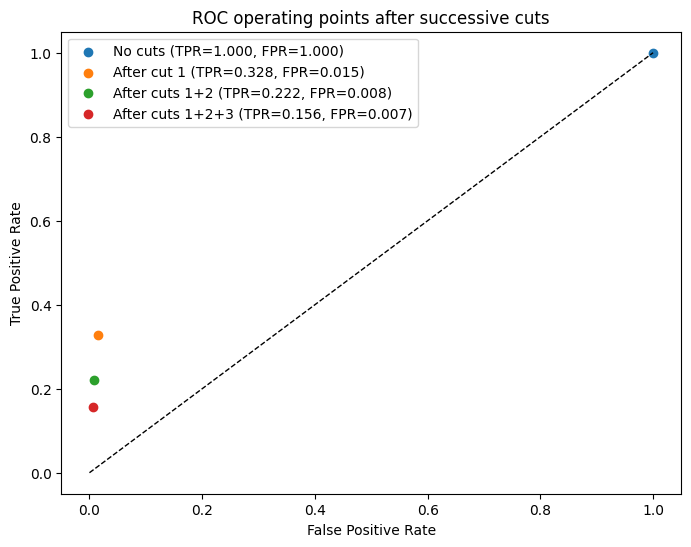

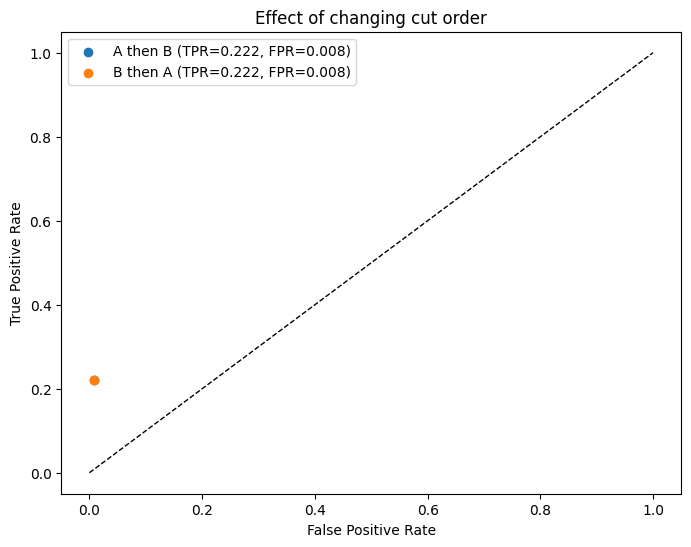

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

def selected_masks(frame, cuts):
    """cuts: list of (variable, strategy, threshold, mu); return rows passing all cuts."""
    mask = np.ones(len(frame), dtype=bool)
    for variable, strategy, threshold, mu in cuts:
        mask &= passes_cut(frame, variable, strategy, threshold, mu)
    return mask

def plot_roc_observables(signal, background, variables, title="ROC curves"):
    fig, ax = plt.subplots(figsize=(7, 6))
    for v in variables:
        s = signal[v].to_numpy()
        b = background[v].to_numpy()
        y = np.r_[np.ones(len(s)), np.zeros(len(b))]
        score = np.r_[s, b]
        fpr, tpr, _ = roc_curve(y, score)
        area = auc(fpr, tpr)
        if area < 0.5:
            fpr, tpr, _ = roc_curve(y, -score)
            area = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{v} (AUC={area:.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=title)
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

plot_roc_observables(df_sig, df_bkg, top3, "ROC curves: top three observables")

def plot_cut_roc(signal, background, cut_orders, title):
    fig, ax = plt.subplots(figsize=(8, 6))

    for label, cuts in cut_orders:
        sm = selected_masks(signal, cuts)
        bm = selected_masks(background, cuts)

        tpr = sm.sum() / len(signal)
        fpr = bm.sum() / len(background)

        ax.scatter(
            [fpr], [tpr],
            label=f"{label} (TPR={tpr:.3f}, FPR={fpr:.3f})"
        )

    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title=title
    )
    ax.legend()
    plt.show()

cuts = []
for v in top3:
    _, strategy, x, es, eb, mu, idx = best_by_var[v]
    cuts.append((v, strategy, x[idx], mu))
plot_cut_roc(df_sig, df_bkg,
             [("No cuts", []), ("After cut 1", cuts[:1]),
              ("After cuts 1+2", cuts[:2]), ("After cuts 1+2+3", cuts)],
             "ROC operating points after successive cuts")

if len(cuts) >= 2:
    plot_cut_roc(df_sig, df_bkg,
                 [("A then B", cuts[:2]), ("B then A", cuts[1::-1])],
                 "Effect of changing cut order")

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

features = VarNames[1:]
sample_n = min(100_000, len(df))
sample = df.sample(sample_n, random_state=7)
X = sample[features].to_numpy(dtype=float)
y = sample["signal"].to_numpy(dtype=int)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X1 = X_scaled[y == 1]
X0 = X_scaled[y == 0]
m1 = X1.mean(axis=0)
m0 = X0.mean(axis=0)

SB = np.outer(m1 - m0, m1 - m0)
SW = (X1 - m1).T @ (X1 - m1) + (X0 - m0).T @ (X0 - m0)
print("S_B shape:", SB.shape, "S_W shape:", SW.shape)

w = np.linalg.pinv(SW) @ (m1 - m0)
F = X_scaled @ w
plt.figure(figsize=(8, 5))
plt.hist(F[y == 1], bins=60, density=True, histtype="step", label="Signal")
plt.hist(F[y == 0], bins=60, density=True, histtype="step", label="Background")
plt.xlabel("F = wᵀx")
plt.ylabel("Density")
plt.title("Fisher linear discriminant")
plt.legend()
plt.tight_layout()
plt.show()

fpr, tpr, thresholds = roc_curve(y, F)
area = auc(fpr, tpr)
if area < 0.5:
    fpr, tpr, thresholds = roc_curve(y, -F)
    area = auc(fpr, tpr)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Fisher discriminant (AUC={area:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve for Fisher discriminant")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for ns, nb in SCENARIOS:
    sig = tpr*ns / np.sqrt(np.maximum(tpr*ns + fpr*nb, 1e-12))
    i = int(np.argmax(sig))
    print(f"NS={ns}, NB={nb}: max significance={sig[i]:.4f}, "
          f"TPR={tpr[i]:.4f}, FPR={fpr[i]:.4f}")

ValueError: Found array with 0 sample(s) (shape=(0, 18)) while a minimum of 1 is required by StandardScaler.